Saved to: ./embed_inbreast_2x2_sample.pdf


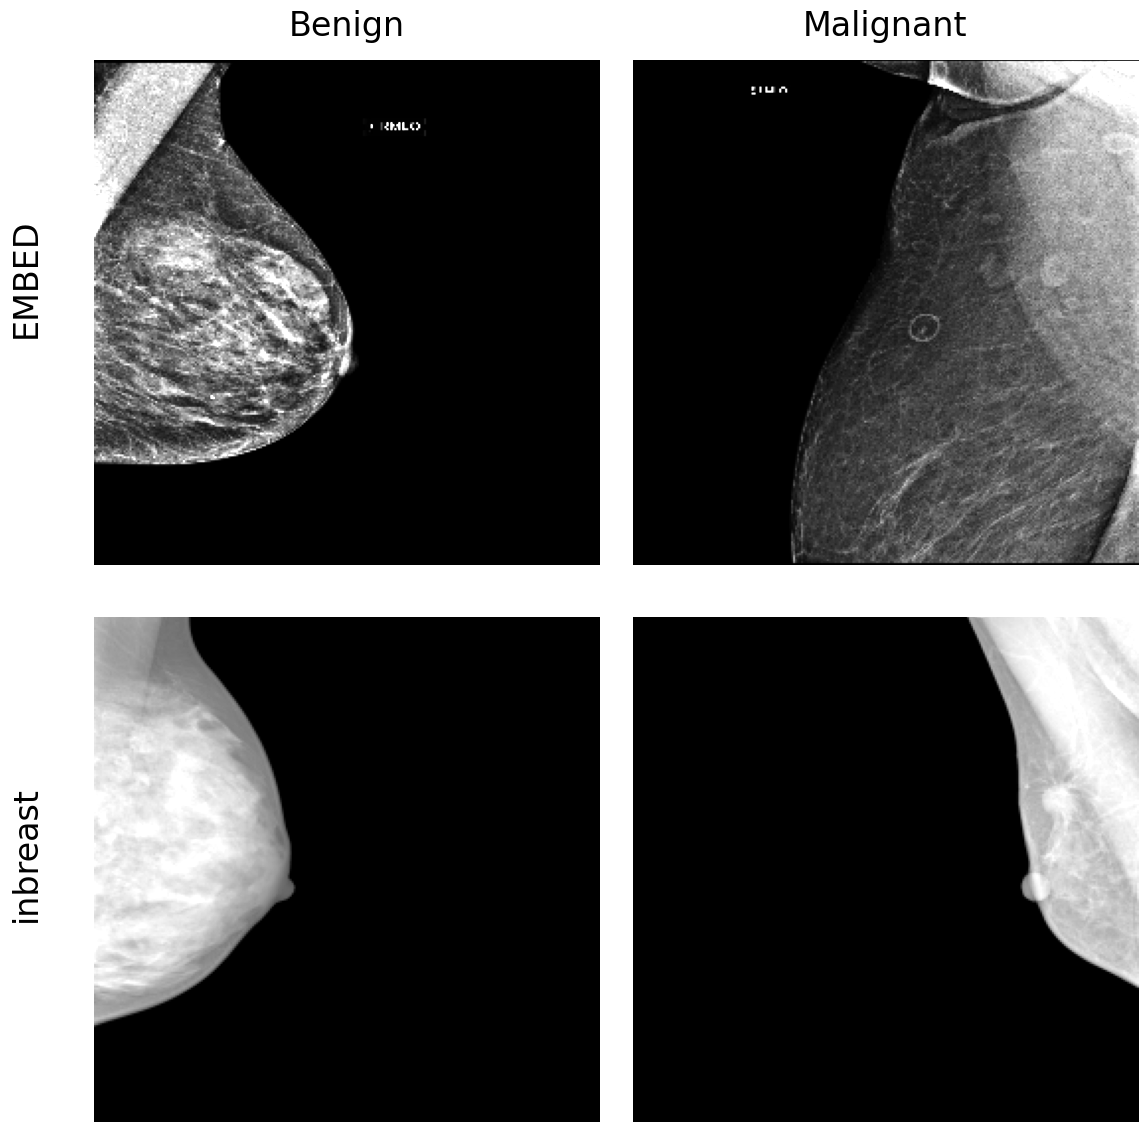

In [1]:
from pathlib import Path
import random

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Styling
# -----------------------------
plt.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 24,
    "axes.labelsize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
})

random.seed(42)

# -----------------------------
# Folder paths
# -----------------------------
paths = {
    ("EMBED", "benign"): Path("/mnt/d/Datasets/EMBED/EMBED_binary_clean/train/original/benign"),
    ("EMBED", "malignant"): Path("/mnt/d/Datasets/EMBED/EMBED_binary_clean/train/original/malignant"),
    ("inbreast", "benign"): Path("/mnt/d/Datasets/inbreast/inbreast_clean_256x256/train/original/benign"),
    ("inbreast", "malignant"): Path("/mnt/d/Datasets/inbreast/inbreast_clean_256x256/train/original/malignant"),
}

# -----------------------------
# Helpers
# -----------------------------
def find_slice_files(folder: Path):
    return sorted(folder.glob("*/slice.nii.gz"))

def load_display_image(nii_path: Path):
    img = nib.load(str(nii_path)).get_fdata()
    img = np.squeeze(img)

    # If 3D, take the center slice along the last axis
    if img.ndim == 3:
        img = img[:, :, img.shape[2] // 2]

    img = np.nan_to_num(img)

    # Robust contrast for display
    vmin, vmax = np.percentile(img, [1, 99])
    if vmax <= vmin:
        vmin, vmax = float(img.min()), float(img.max() if img.max() > img.min() else img.min() + 1.0)

    return img, vmin, vmax

def sample_one(folder: Path):
    files = find_slice_files(folder)
    if not files:
        raise FileNotFoundError(f"No slice.nii.gz files found in: {folder}")
    return random.choice(files)

# -----------------------------
# Make figure
# -----------------------------
row_specs = ["EMBED", "inbreast"]
col_specs = ["benign", "malignant"]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for i, row_name in enumerate(row_specs):
    for j, col_name in enumerate(col_specs):
        ax = axes[i, j]
        nii_path = sample_one(paths[(row_name, col_name)])
        img, vmin, vmax = load_display_image(nii_path)

        ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
        ax.axis("off")

        if i == 0:
            ax.set_title(col_name.capitalize(), pad=18)

# Row labels
fig.text(0.03, 0.74, "EMBED", va="center", rotation=90)
fig.text(0.03, 0.26, "inbreast", va="center", rotation=90)

plt.tight_layout(rect=[0.07, 0.0, 1.0, 1.0])

out_path = "./embed_inbreast_2x2_sample.pdf"
fig.savefig(out_path, bbox_inches="tight")
print("Saved to:", out_path)

plt.show()

Saved to: ./embed_inbreast_8panel_samples.pdf


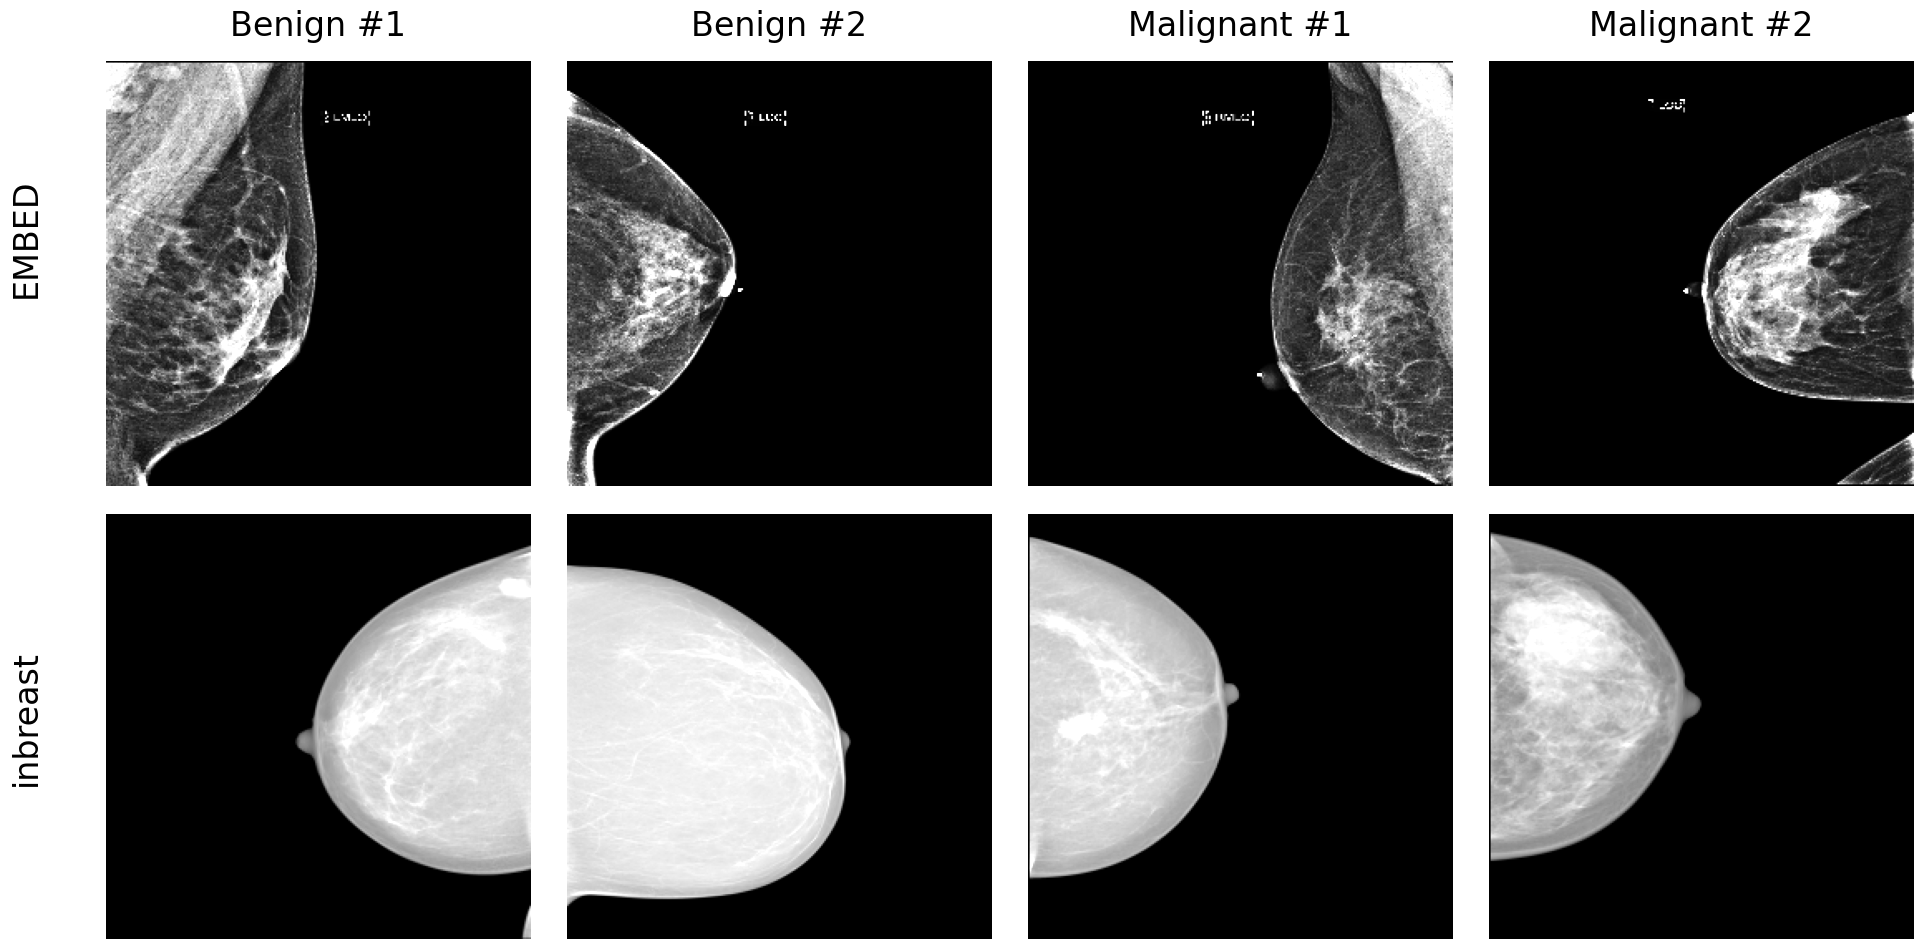

In [5]:
from pathlib import Path
import random

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Styling
# -----------------------------
plt.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 24,
    "axes.labelsize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
})

random.seed(44)

# -----------------------------
# Folder paths
# -----------------------------
paths = {
    ("EMBED", "benign"): Path("/mnt/d/Datasets/EMBED/EMBED_binary_clean/train/original/benign"),
    ("EMBED", "malignant"): Path("/mnt/d/Datasets/EMBED/EMBED_binary_clean/train/original/malignant"),
    ("inbreast", "benign"): Path("/mnt/d/Datasets/inbreast/inbreast_clean_256x256/train/original/benign"),
    ("inbreast", "malignant"): Path("/mnt/d/Datasets/inbreast/inbreast_clean_256x256/train/original/malignant"),
}

# -----------------------------
# Helpers
# -----------------------------
def find_slice_files(folder: Path):
    return sorted(folder.glob("*/slice.nii.gz"))

def load_display_image(nii_path: Path):
    img = nib.load(str(nii_path)).get_fdata()
    img = np.squeeze(img)

    # If 3D -> take center slice
    if img.ndim == 3:
        img = img[:, :, img.shape[2] // 2]

    img = np.nan_to_num(img)

    # Robust contrast
    vmin, vmax = np.percentile(img, [1, 99])

    if vmax <= vmin:
        vmin = float(img.min())
        vmax = float(img.max()) if img.max() > img.min() else vmin + 1.0

    return img, vmin, vmax

def sample_n(folder: Path, n=2):
    files = find_slice_files(folder)

    if len(files) < n:
        raise ValueError(f"Not enough files in {folder}")

    return random.sample(files, n)

# -----------------------------
# Figure setup
# -----------------------------
row_specs = ["EMBED", "inbreast"]
col_specs = ["benign", "malignant"]

# 2 rows × 4 columns
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, dataset_name in enumerate(row_specs):

    col_idx = 0

    for cls_name in col_specs:

        sampled_files = sample_n(paths[(dataset_name, cls_name)], n=2)

        for sample_num, nii_path in enumerate(sampled_files):

            ax = axes[i, col_idx]

            img, vmin, vmax = load_display_image(nii_path)

            ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
            ax.axis("off")

            # Top-row titles only
            if i == 0:
                ax.set_title(
                    f"{cls_name.capitalize()} #{sample_num + 1}",
                    pad=18
                )

            col_idx += 1

# -----------------------------
# Row labels
# -----------------------------
fig.text(0.03, 0.74, "EMBED", va="center", rotation=90)
fig.text(0.03, 0.26, "inbreast", va="center", rotation=90)

plt.tight_layout(rect=[0.06, 0.0, 1.0, 1.0])

out_path = "./embed_inbreast_8panel_samples.pdf"

fig.savefig(out_path, bbox_inches="tight")

print("Saved to:", out_path)

plt.show()